# Panorama Image Stitching con OpenCV

**Autores:** Antía Sande Fernández, Sergio Medina Hernández y Martín Hernández Castaño
**Asignatura:** Fundamentos de Análisis de Imagen · Grado en Ciencia de Datos e Inteligencia Artificial (UPM) · curso 2025-26

Este notebook implementa, sin usar la clase `cv2.Stitcher`, todo el proceso para unir varias fotografías en una panorámica:

| Parte | Problema | Técnicas |
|---|---|---|
| **1** | Localizar un cartel plano en una foto y sustituirlo por otra imagen con la perspectiva correcta | Detectores y descriptores locales, emparejamiento, homografía con RANSAC |
| **2** | Unir 5 fotos ordenadas en una panorámica planar | Homografías encadenadas a una imagen de referencia, *feathering* |
| **3** | Unir 7 fotos en una panorámica *wide-view*, aunque estén desordenadas | Proyección cilíndrica, estimación de la focal, traslaciones robustas, ordenación automática y comparación de 6 técnicas de *blending* |

Todo el código reutilizable está en [`src/panorama.py`](../src/panorama.py). El notebook se centra en los experimentos y en los resultados.

In [1]:
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))
import panorama as P

IMG_DIR = Path("../images")
FIG_DIR = Path("../docs/img")
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})
pd.set_option("display.precision", 1)
print("OpenCV", cv2.__version__)


def leer(nombre):
    return cv2.cvtColor(cv2.imread(str(IMG_DIR / f"{nombre}.jpg")), cv2.COLOR_BGR2RGB)


def mostrar(imgs, titulos=None, cols=None, alto=4.0, guardar=None):
    # Muestra una lista de imágenes en una cuadrícula (y opcionalmente la guarda en docs/img).
    imgs = imgs if isinstance(imgs, list) else [imgs]
    titulos = titulos or [""] * len(imgs)
    cols = cols or len(imgs)
    filas = int(np.ceil(len(imgs) / cols))
    ratio = np.mean([i.shape[1] / i.shape[0] for i in imgs])
    fig, axes = plt.subplots(filas, cols, figsize=(min(alto * ratio * cols, 18), alto * filas), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, img, t in zip(axes.ravel(), imgs, titulos):
        ax.imshow(img)
        ax.set_title(t)
    plt.tight_layout()
    if guardar:
        plt.savefig(FIG_DIR / guardar, dpi=110, bbox_inches="tight")
    plt.show()


def guardar_jpg(img, nombre, ancho_max=2400):
    # Guarda una imagen (p. ej. una panorámica) en docs/img, reducida para el README.
    s = min(1.0, ancho_max / img.shape[1])
    peq = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    cv2.imwrite(str(FIG_DIR / nombre), cv2.cvtColor(peq, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 88])

OpenCV 5.0.0


---
# Parte 1 · Detección de un objeto plano e inserción con homografías

El objetivo es localizar un cartel (el **modelo**) dentro de una foto de una marquesina (la **escena**) y sustituirlo por otro cartel (la imagen a **insertar**) con la perspectiva correcta.

**Proceso:**

1. **Detección y descripción** de puntos característicos en el modelo y en la escena.
2. **Emparejamiento**: para cada descriptor del modelo se buscan sus 2 vecinos más cercanos en la escena (`knnMatch`, k = 2). Se aplica el **test de razón de Lowe** (0,75): un emparejamiento solo se acepta si el mejor vecino está claramente más cerca que el segundo.
3. **Homografía con RANSAC**: con los emparejamientos buenos se estima la matriz 3×3 que lleva el plano del modelo al de la escena, descartando los emparejamientos erróneos (*outliers*).
4. **Inserción**: la nueva imagen se deforma con esa homografía (`warpPerspective`) y se pega en la escena.

> La escena original es una foto de 12 Mpx (3024×4032). Se reduce a la mitad (1512×2016), la misma resolución que el modelo y las fotos del panorama. Así se puede ejecutar KAZE sin agotar la memoria y se compara a una escala parecida.

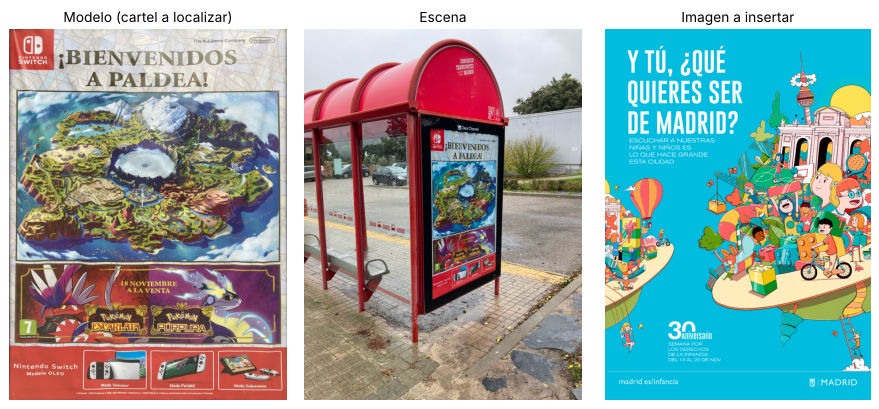

In [2]:
modelo, insertar = leer("pkmn"), leer("ayto")
escena = cv2.resize(leer("bus"), None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
mostrar([modelo, escena, insertar], ["Modelo (cartel a localizar)", "Escena", "Imagen a insertar"], alto=4.5)

### Combinaciones evaluadas

El enunciado pide comparar detectores de **esquinas frente a blobs**, descriptores **binarios frente a de coma flotante** y emparejamiento por **fuerza bruta frente a FLANN**. Se prueban 6 combinaciones de detector y descriptor que cubren las cuatro casillas, cada una con los dos *matchers* (12 experimentos en total):

| | **Descriptor binario** (distancia Hamming) | **Descriptor float** (distancia L2) |
|---|---|---|
| **Esquinas** | ORB (FAST + rBRIEF), BRISK (AGAST + BRISK) | GFTT+SIFT (esquinas de Harris + descriptor SIFT) |
| **Blobs** | AKAZE (Hessiano no lineal + M-LDB) | SIFT (diferencia de gaussianas), KAZE (Hessiano no lineal) |

- **BF** (*brute force*) compara cada descriptor con todos los demás: es exacto.
- **FLANN** hace una búsqueda aproximada: usa árboles KD con los descriptores float y LSH (*Locality Sensitive Hashing*) con los binarios.

Para que la comparación sea justa, cada detector se queda con sus **4.000 puntos más fuertes** (BRISK, por ejemplo, detecta más de 40.000).

**¿Cómo se mide la calidad?** No hay una posición "real" del cartel con la que comparar, pero las combinaciones que funcionan coinciden en ella con un margen de pocos píxeles. Por eso se toma como referencia la **mediana** de las esquinas proyectadas por todas ellas, y para cada experimento se calcula su **desviación media respecto al consenso** en píxeles.

In [3]:
resultados_p1 = {}
filas = []
for nombre in P.METODOS:
    metodo = P.crear_metodo(nombre)
    for estrategia in ["bf", "flann"]:
        r = P.insertar_en_plano(modelo, escena, insertar, metodo, estrategia)
        resultados_p1[(nombre, estrategia)] = r
        filas.append(r["metricas"])
tabla_p1 = pd.DataFrame(filas)

# Consenso: mediana de las esquinas proyectadas por los experimentos con >= 15 inliers
esquinas = {k: P.contorno_proyectado(r["H"], modelo.shape)
            for k, r in resultados_p1.items() if r["H"] is not None and r["metricas"]["Inliers"] >= 15}
consenso = np.median(np.stack(list(esquinas.values())), axis=0)
tabla_p1["Desviación (px)"] = [
    np.linalg.norm(P.contorno_proyectado(r["H"], modelo.shape) - consenso, axis=1).mean() if r["H"] is not None else np.nan
    for r in resultados_p1.values()
]
tabla_p1["t total (ms)"] = tabla_p1[["t detección (ms)", "t descripción (ms)", "t matching (ms)", "t RANSAC (ms)"]].sum(axis=1)
tabla_p1["ms / 1000 KP"] = (tabla_p1["t detección (ms)"] + tabla_p1["t descripción (ms)"]) / ((tabla_p1["KP modelo"] + tabla_p1["KP escena"]) / 1000)

cols = ["Método", "Detector", "Descriptor", "Matcher", "KP modelo", "KP escena", "Matches", "Inliers", "% inliers",
        "Desviación (px)", "t detección (ms)", "t descripción (ms)", "t matching (ms)", "t RANSAC (ms)", "ms / 1000 KP"]
display(tabla_p1[cols].style.format(precision=1)
        .background_gradient(subset=["Inliers"], cmap="Greens")
        .background_gradient(subset=["t detección (ms)"], cmap="Oranges")
        .hide(axis="index"))

Método,Detector,Descriptor,Matcher,KP modelo,KP escena,Matches,Inliers,% inliers,Desviación (px),t detección (ms),t descripción (ms),t matching (ms),t RANSAC (ms),ms / 1000 KP
ORB,esquinas,binario,BF,4000,4000,31,9,29.0,3.3,99.9,34.7,70.1,13.8,16.8
ORB,esquinas,binario,FLANN,4000,4000,52,10,19.2,35.2,81.8,33.6,69.2,32.7,14.4
BRISK,esquinas,binario,BF,4000,4000,70,46,65.7,1.6,1002.4,69.7,73.5,1.2,134.0
BRISK,esquinas,binario,FLANN,4000,4000,84,53,63.1,1.4,1052.8,75.4,129.9,1.7,141.0
GFTT+SIFT,esquinas,float,BF,3801,4000,0,0,0.0,nan,91.8,3031.5,176.5,0.0,400.4
GFTT+SIFT,esquinas,float,FLANN,3801,4000,1,0,0.0,nan,72.9,3081.2,98.7,0.0,404.3
SIFT,blobs,float,BF,4000,4000,156,106,67.9,2.0,1172.1,590.2,161.4,1.3,220.3
SIFT,blobs,float,FLANN,4000,4000,175,116,66.3,1.1,1030.1,634.1,106.9,1.0,208.0
KAZE,blobs,float,BF,4000,4000,22,14,63.6,9.2,6011.8,3161.3,99.6,0.9,1146.6
KAZE,blobs,float,FLANN,4000,4000,40,19,47.5,9.9,5419.3,3103.2,93.3,4.7,1065.3


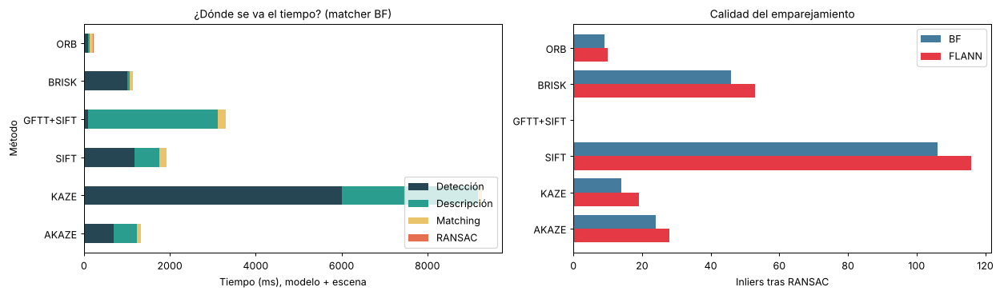

In [4]:
# Desglose de tiempos (con BF) y nº de inliers por método
bf = tabla_p1[tabla_p1["Matcher"] == "BF"].set_index("Método")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
bf[["t detección (ms)", "t descripción (ms)", "t matching (ms)", "t RANSAC (ms)"]].plot.barh(
    stacked=True, ax=ax1, color=["#264653", "#2a9d8f", "#e9c46a", "#e76f51"])
ax1.set_xlabel("Tiempo (ms), modelo + escena")
ax1.set_title("¿Dónde se va el tiempo? (matcher BF)")
ax1.invert_yaxis()
ax1.legend(["Detección", "Descripción", "Matching", "RANSAC"], loc="lower right")

ancho = 0.38
y = np.arange(len(P.METODOS))
for k, (est, color) in enumerate([("BF", "#457b9d"), ("FLANN", "#e63946")]):
    sub = tabla_p1[tabla_p1["Matcher"] == est]
    ax2.barh(y + (k - 0.5) * ancho, sub["Inliers"], height=ancho, color=color, label=est)
ax2.set_yticks(y, tabla_p1["Método"].unique())
ax2.invert_yaxis()
ax2.set_xlabel("Inliers tras RANSAC")
ax2.set_title("Calidad del emparejamiento")
ax2.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "parte1_comparativa.png", dpi=110, bbox_inches="tight")
plt.show()

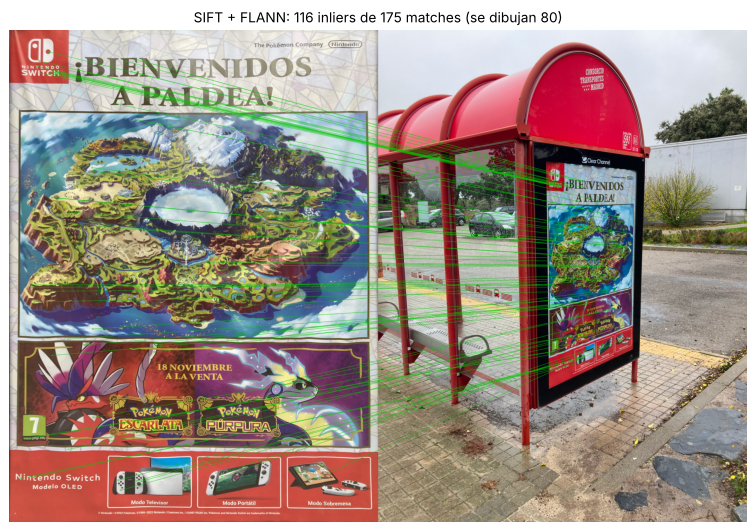

In [5]:
# Emparejamientos de la mejor combinación (inliers en verde) y resultado de la inserción
mejor_p1 = tabla_p1.sort_values(["Inliers", "t total (ms)"], ascending=[False, True]).iloc[0]
clave = (mejor_p1["Método"].lower().replace("+", "_"), mejor_p1["Matcher"].lower())
r = resultados_p1[clave]
inliers = [m for m, ok in zip(r["matches"], r["mascara"].ravel()) if ok]
vis = cv2.drawMatches(modelo, r["modelo"].kps, escena, r["escena"].kps, inliers[:80], None,
                      matchColor=(0, 200, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
mostrar(vis, [f"{mejor_p1['Método']} + {mejor_p1['Matcher']}: {len(inliers)} inliers de {len(r['matches'])} matches (se dibujan 80)"], alto=6)

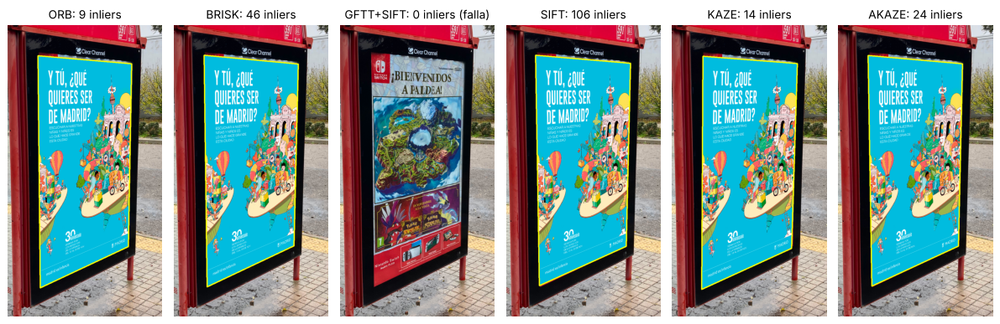

In [6]:
# Resultado de la inserción para cada detector (matcher BF), recortado alrededor del cartel
x0, y0 = consenso.min(axis=0).astype(int) - 120
x1, y1 = consenso.max(axis=0).astype(int) + 120
recortes, titulos = [], []
for nombre in P.METODOS:
    r = resultados_p1[(nombre, "bf")]
    img = r["resultado"] if r["resultado"] is not None else escena.copy()
    img = img.copy()
    if r["H"] is not None:
        cv2.polylines(img, [P.contorno_proyectado(r["H"], modelo.shape).astype(np.int32)], True, (255, 255, 0), 4)
    recortes.append(img[max(y0, 0):y1, max(x0, 0):x1])
    m = r["metricas"]
    titulos.append(f"{m['Método']}: {m['Inliers']} inliers" + ("" if r["H"] is not None else " (falla)"))
mostrar(recortes, titulos, cols=6, alto=4.2, guardar="parte1_insercion.png")

### Discusión de la Parte 1

- **Los blobs con descriptor float (SIFT) dan el emparejamiento más sólido:** con unos 100 inliers, son los que mejor resuelven la gran diferencia de escala entre el modelo (2016 px de alto) y el cartel en la escena (≈900 px).
- **AKAZE (blob + binario) es el mejor compromiso:** más rápido que SIFT, con una inserción igual de precisa y menos inliers.
- **Las esquinas sin escala fallan.** GFTT+SIFT no consigue ni un emparejamiento válido, aunque usa el mismo descriptor que SIFT: el detector de Harris/Shi-Tomasi no estima la escala del punto, así que los descriptores del modelo y de la escena describen regiones de tamaños distintos. ORB y BRISK también detectan esquinas, pero lo hacen sobre una **pirámide de escalas**, y por eso sí funcionan. ORB, eso sí, con muy pocos inliers.
- **Tiempos:** la **detección** domina el coste en casi todos los métodos. KAZE es con diferencia el más lento (≈9 s), por la difusión no lineal que construye su espacio de escalas. ORB es el más rápido (≈0,1 s). El *matching* y RANSAC son despreciables con 4.000 puntos por imagen.
- **BF frente a FLANN:** con 4.000 descriptores, FLANN no ahorra tiempo de forma sistemática, porque construir el índice cuesta casi lo mismo que la búsqueda exhaustiva. Sí devuelve algo más de *matches*. FLANN compensa cuando hay decenas de miles de descriptores o se empareja contra muchas imágenes.
- **Precisión:** la mayoría de las combinaciones sitúan el cartel a **1–3 px del consenso**, así que la inserción es visualmente correcta. Las excepciones son las que tienen menos inliers: KAZE (≈9 px) y, sobre todo, ORB + FLANN (≈35 px, con solo 10 inliers). Con tan pocos puntos, RANSAC tiene poco margen para estimar bien la homografía.

---
# Parte 2 · Panorámica planar con 5 imágenes ordenadas

Las 5 fotos (`1.jpg` … `5.jpg`) se hicieron girando la cámara de izquierda a derecha. Se procede así:

1. Se calcula la **homografía H<sub>i</sub>** entre cada par de fotos consecutivas *i → i+1* (características + RANSAC).
2. La foto central se deja **sin deformar** y el resto se proyectan sobre su plano encadenando las homografías.
3. Se calcula el **lienzo** que contiene todas las fotos proyectadas, se deforman (`warpPerspective`) y se mezclan con *feathering*.

**Encadenado de homografías.** Si H<sub>i</sub> lleva la foto *i* a la *i+1*, la transformación T<sub>i</sub> que lleva la foto *i* a la referencia es:

- a la izquierda de la referencia: **T<sub>i</sub> = T<sub>i+1</sub> · H<sub>i</sub>** (primero se aplica H<sub>i</sub> y después T<sub>i+1</sub>);
- a la derecha: **T<sub>i</sub> = T<sub>i−1</sub> · H<sub>i−1</sub><sup>−1</sup>**.

El orden del producto importa porque las homografías no conmutan (ver apartado 2.3).

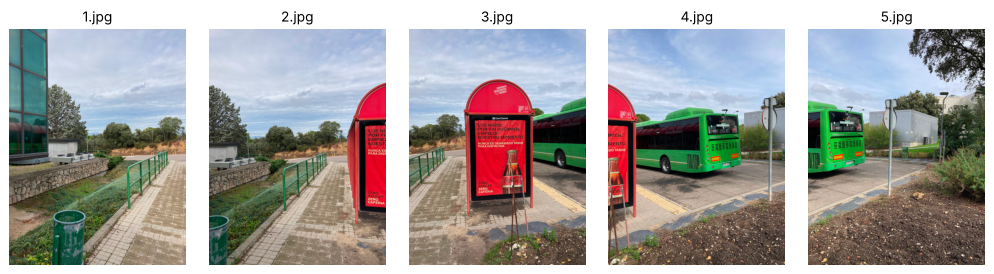

In [7]:
imgs5 = [leer(str(i)) for i in range(1, 6)]
mostrar(imgs5, [f"{i}.jpg" for i in range(1, 6)], alto=3)

### 2.1 Comparación de detectores, descriptores y matchers

Se repiten las 12 combinaciones de la Parte 1 sobre los 4 pares de fotos consecutivas. Las métricas son:

- **Inliers medios** y del **par más débil**. El par con menos inliers es el eslabón débil de la cadena: si su homografía falla, falla todo el panorama.
- **Error de reproyección**: distancia media, en píxeles, entre cada inlier proyectado con la homografía y su pareja.
- **Tiempos** de detección, descripción y *matching* de las 5 imágenes, y **coste por cada 1.000 puntos**.

In [8]:
filas = []
for nombre in P.METODOS:
    for estrategia in ["bf", "flann"]:
        _, info = P.stitching_planar(imgs5, nombre, estrategia, componer=False, min_inliers=0)
        pares = info["pares"]
        filas.append({
            "Método": info["metodo"].nombre, "Detector": info["metodo"].tipo_detector,
            "Descriptor": info["metodo"].tipo_descriptor, "Matcher": estrategia.upper(),
            "KP / imagen": np.mean(info["kps"]), "Matches medios": pares["Matches"].mean(),
            "Inliers medios": pares["Inliers"].mean(), "Inliers par más débil": pares["Inliers"].min(),
            "Error reproy. (px)": pares["Error reproy. (px)"].mean(),
            "t detección (s)": info["t_deteccion"], "t descripción (s)": info["t_descripcion"],
            "t matching (s)": pares["t matching (ms)"].sum() / 1000,
            "ms / 1000 KP": 1000 * (info["t_deteccion"] + info["t_descripcion"]) / (sum(info["kps"]) / 1000),
            "t total (s)": info["tiempo_total"],
        })
bench = pd.DataFrame(filas).sort_values("Inliers par más débil", ascending=False)
display(bench.style.format(precision=2, subset=["Error reproy. (px)", "t detección (s)", "t descripción (s)",
                                               "t matching (s)", "t total (s)"])
        .format(precision=0, subset=["KP / imagen", "Matches medios", "Inliers medios", "ms / 1000 KP"])
        .background_gradient(subset=["Inliers par más débil"], cmap="Greens")
        .background_gradient(subset=["t total (s)"], cmap="Oranges")
        .hide(axis="index"))

Método,Detector,Descriptor,Matcher,KP / imagen,Matches medios,Inliers medios,Inliers par más débil,Error reproy. (px),t detección (s),t descripción (s),t matching (s),ms / 1000 KP,t total (s)
KAZE,blobs,float,BF,4000,738,414,243,1.22,11.90,7.29,0.36,960,19.57
KAZE,blobs,float,FLANN,4000,762,416,233,1.41,13.38,8.24,0.39,1081,22.03
AKAZE,blobs,binario,FLANN,4000,744,402,209,1.23,1.58,1.34,0.50,146,3.44
AKAZE,blobs,binario,BF,4000,730,392,191,1.41,1.61,1.43,0.40,152,3.47
SIFT,blobs,float,FLANN,4000,641,339,187,1.26,1.79,1.28,0.43,154,3.53
SIFT,blobs,float,BF,4000,631,340,178,1.05,2.69,1.49,0.64,209,4.85
ORB,esquinas,binario,BF,4000,410,277,137,1.59,0.22,0.09,0.33,15,0.65
ORB,esquinas,binario,FLANN,4000,451,305,134,1.47,0.24,0.09,0.26,16,0.61
BRISK,esquinas,binario,FLANN,4000,500,296,132,1.15,2.62,0.17,0.43,139,3.23
BRISK,esquinas,binario,BF,4000,485,286,128,1.41,2.79,0.17,0.28,148,3.26


Combinación elegida: AKAZE + FLANN (209 inliers en el par más débil, 3.4 s)


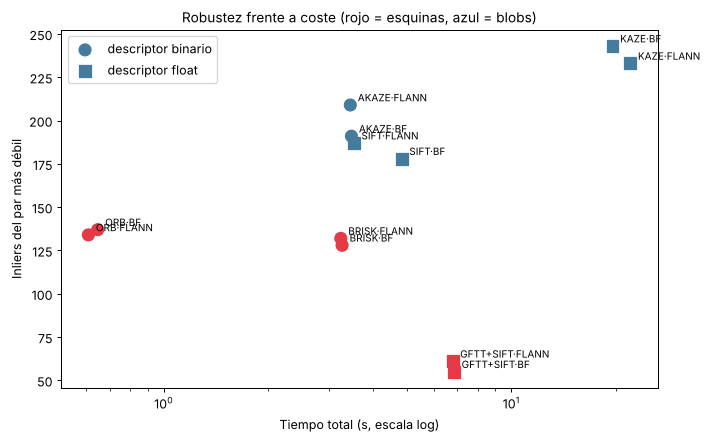

In [9]:
# Criterio de elección: el par más débil más robusto entre los métodos que tardan menos de 5 s
rapidos = bench[bench["t total (s)"] < 5]
elegido = rapidos.iloc[0]
MEJOR_METODO = elegido["Método"].lower().replace("+", "_")
MEJOR_MATCHER = elegido["Matcher"].lower()
print(f"Combinación elegida: {elegido['Método']} + {elegido['Matcher']} "
      f"({elegido['Inliers par más débil']:.0f} inliers en el par más débil, {elegido['t total (s)']:.1f} s)")

fig, ax = plt.subplots(figsize=(8, 5))
for desc, marca in [("binario", "o"), ("float", "s")]:
    sub = bench[bench["Descriptor"] == desc]
    ax.scatter(sub["t total (s)"], sub["Inliers par más débil"], s=90, marker=marca, label=f"descriptor {desc}",
               c=["#e63946" if d == "esquinas" else "#457b9d" for d in sub["Detector"]])
for _, f in bench.iterrows():
    ax.annotate(f"{f['Método']}·{f['Matcher']}", (f["t total (s)"], f["Inliers par más débil"]),
                textcoords="offset points", xytext=(6, 3), fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Tiempo total (s, escala log)")
ax.set_ylabel("Inliers del par más débil")
ax.set_title("Robustez frente a coste (rojo = esquinas, azul = blobs)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "parte2_benchmark.png", dpi=110, bbox_inches="tight")
plt.show()

- **AKAZE + FLANN** ofrece el mejor equilibrio: es el segundo método más robusto (más de 200 inliers en el par más débil) y tarda unos 3 s para las 5 fotos.
- **KAZE** es el más robusto (≈240 inliers en el par más débil), pero es 5 veces más lento.
- **SIFT** queda cerca de AKAZE en robustez y tiempo.
- **ORB** es con diferencia el más rápido (≈0,6 s) y su par más débil sigue teniendo más de 130 inliers. En una aplicación en tiempo real sería la elección lógica.
- **GFTT+SIFT** vuelve a ser el peor: sin estimación de escala, los descriptores no son comparables cuando cambia el punto de vista. Además es lento, porque calcular el descriptor SIFT sobre esos puntos sale caro.
- Entre BF y FLANN apenas hay diferencias de calidad. Con estos tamaños, FLANN no supone una ganancia clara de tiempo.

A partir de aquí se usa la combinación elegida (**AKAZE + FLANN**), también en la Parte 3, como pide el enunciado.

### 2.2 Panorámica final

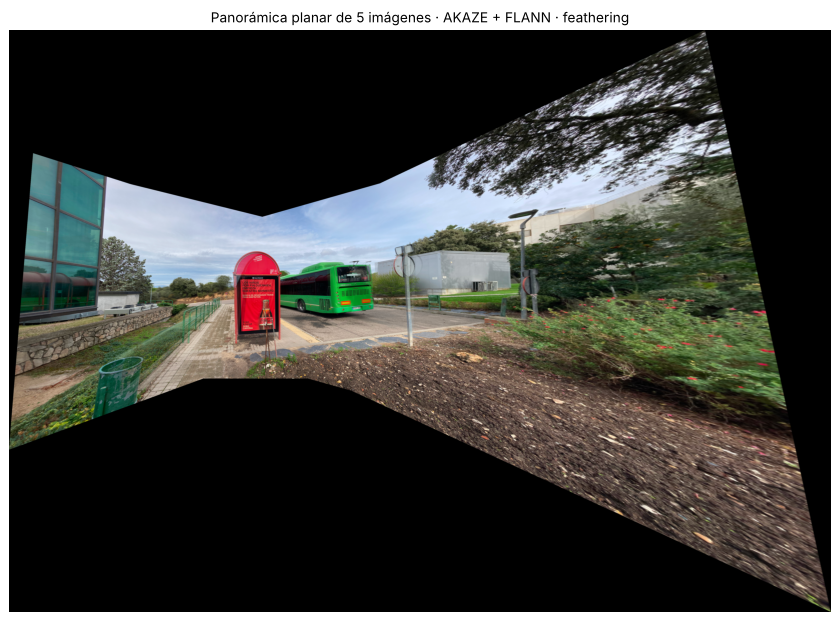

Par,Matches,Inliers,Error reproy. (px),t matching (ms),t RANSAC (ms)
0→1,1480,926,1.48,120.43,1.34
1→2,619,237,0.97,110.14,4.73
2→3,458,209,1.63,147.41,2.49
3→4,420,238,0.84,105.38,1.23


In [10]:
pano5, info5 = P.stitching_planar(imgs5, MEJOR_METODO, MEJOR_MATCHER, blending="feather")
mostrar(pano5, [f"Panorámica planar de 5 imágenes · {elegido['Método']} + {elegido['Matcher']} · feathering"], alto=7)
guardar_jpg(pano5, "parte2_panorama.jpg")
display(info5["pares"].style.format(precision=2).hide(axis="index"))

La panorámica queda bien alineada, pero se ve la limitación de la proyección planar: cuanto más lejos está una foto de la referencia, más se estira (las de los extremos ocupan casi la mitad del lienzo). Con un campo de visión mayor, las fotos de los extremos acabarían proyectándose al infinito. Por eso la Parte 3 usa una proyección cilíndrica.

### 2.3 Corrección respecto a la entrega original: el orden del encadenado

En la versión entregada, las homografías se encadenaban como `T[i] = H[i] @ T[i+1]`, es decir, en el orden contrario al correcto. Con la referencia en el centro, las fotos contiguas a ella no se ven afectadas, porque T = H y el resultado es el mismo. Las de los extremos, en cambio, se colocan en una posición equivocada.

Para medirlo, se proyectan al lienzo los inliers de cada par con las transformaciones de ambas fotos y se mide cuánto se separan: si la alineación es perfecta, cada punto de una foto debe caer encima de su pareja de la otra.

Par,Error encadenado correcto (px),Error encadenado original (px)
1→2,3.0,20.7
2→3,1.4,1.4
3→4,1.6,1.6
4→5,4.8,33.1


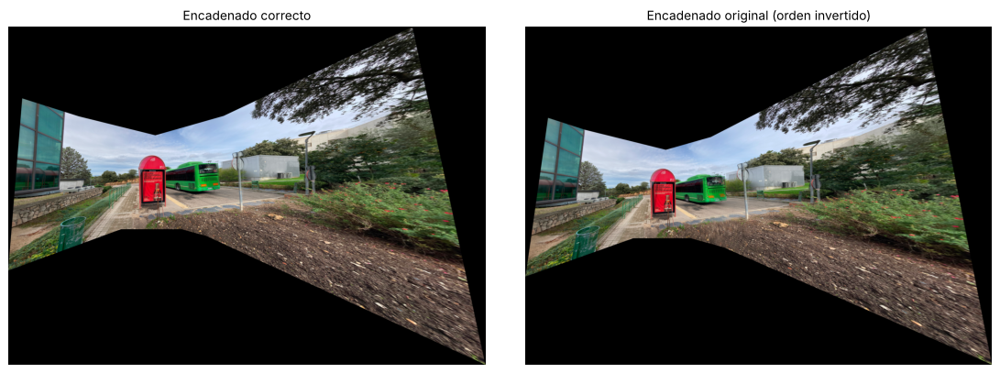

In [11]:
def encadenado_original(H, ref):
    # Versión de la entrega: producto en orden invertido
    n = len(H) + 1
    T = [None] * n
    T[ref] = np.eye(3)
    for i in range(ref - 1, -1, -1):
        T[i] = H[i] @ T[i + 1]
    for i in range(ref + 1, n):
        T[i] = np.linalg.inv(H[i - 1]) @ T[i - 1]
    return T


def error_en_lienzo(info, T):
    # Separación media (px) en el lienzo entre cada inlier y su pareja, por par de imágenes
    errores = []
    feats, m = info["feats"], info["metodo"]
    for i in range(len(T) - 1):
        a, b = feats[i], feats[i + 1]
        matches, _ = P.emparejar(a.desc, b.desc, m.tipo_descriptor, MEJOR_MATCHER)
        _, mascara, _, _ = P.homografia_ransac(a.kps, b.kps, matches)
        pa, pb = P.puntos(a.kps, b.kps, matches)
        sel = mascara.ravel().astype(bool)
        qa = cv2.perspectiveTransform(pa[sel].reshape(-1, 1, 2), T[i]).reshape(-1, 2)
        qb = cv2.perspectiveTransform(pb[sel].reshape(-1, 1, 2), T[i + 1]).reshape(-1, 2)
        errores.append(np.linalg.norm(qa - qb, axis=1).mean())
    return errores


T_mal = encadenado_original(info5["H"], 2)
comparacion = pd.DataFrame({
    "Par": [f"{i + 1}→{i + 2}" for i in range(4)],
    "Error encadenado correcto (px)": error_en_lienzo(info5, info5["T"]),
    "Error encadenado original (px)": error_en_lienzo(info5, T_mal),
})
display(comparacion.style.format(precision=1).hide(axis="index"))

pano_mal, _ = P.stitching_planar(imgs5, MEJOR_METODO, MEJOR_MATCHER, blending="feather", encadenar=encadenado_original)
mostrar([pano5, pano_mal], ["Encadenado correcto", "Encadenado original (orden invertido)"], cols=2, alto=4.5,
        guardar="parte2_encadenado.png")

Los pares contiguos a la referencia (2→3 y 3→4) son idénticos en los dos casos. En los pares exteriores (1→2 y 4→5), en cambio, el encadenado original desplaza las fotos de los extremos decenas de píxeles respecto a su posición correcta. En la imagen esto se traduce en **fantasmas** (objetos duplicados y semitransparentes) en las zonas de solape y en una geometría distinta del panorama.

---
# Parte 3 · Panorámica *wide-view* con 7 imágenes

### 3.1 Por qué no basta con la proyección planar

Con 7 fotos el campo de visión total supera los 180°. En una proyección planar, las fotos de los extremos tendrían que proyectarse sobre un plano casi paralelo a su dirección de visión, y el lienzo crece sin límite.

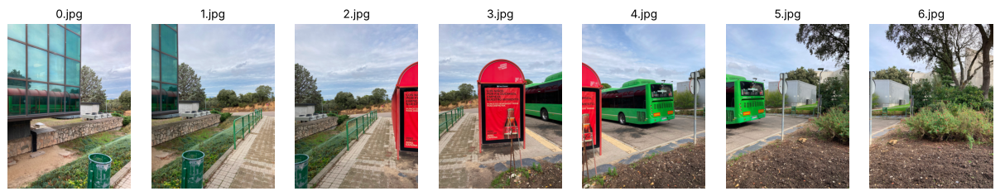

Proyección planar con 7 imágenes → Lienzo demasiado grande (14998x12232): la proyección planar ha divergido


In [12]:
imgs7 = [leer(str(i)) for i in range(7)]
mostrar(imgs7, [f"{i}.jpg" for i in range(7)], alto=2.6)
try:
    P.stitching_planar(imgs7, MEJOR_METODO, MEJOR_MATCHER)
except RuntimeError as e:
    print("Proyección planar con 7 imágenes →", e)

### 3.2 Proyección cilíndrica y estimación de la distancia focal

La solución es proyectar cada foto sobre un **cilindro** (o una esfera) centrado en la cámara. Si la cámara solo gira alrededor de su eje vertical, en coordenadas cilíndricas el paso de una foto a la siguiente es una **traslación horizontal**, así que basta con estimar un desplazamiento (dx, dy) por par en lugar de una homografía completa. Es un modelo mucho más estable y sin deriva de perspectiva.

Para proyectar hace falta la **distancia focal f** en píxeles. La versión entregada usaba una heurística, f = 0,8·ancho ≈ 1.210 px. Como las fotos no conservan los metadatos EXIF, aquí se **estima la focal**: se prueban varios valores y se elige el que maximiza los inliers de traslación entre fotos consecutivas. Con la focal correcta, tras la proyección el movimiento entre fotos es casi una traslación pura y RANSAC encuentra más puntos coherentes.

In [13]:
F, tabla_focal = P.estimar_focal(imgs7, MEJOR_METODO, MEJOR_MATCHER)
display(tabla_focal.style.format(precision=1).highlight_max(subset=["Inliers totales"], color="#d8f3dc").hide(axis="index"))
print(f"Focal elegida: f = {F:.0f} px (la heurística 0,8·ancho daría {0.8 * imgs7[0].shape[1]:.0f} px)")

factor,f (px),Inliers totales,Inliers par más débil
0.8,1209.6,489,22
0.9,1360.8,618,31
1.0,1512.0,634,45
1.1,1663.2,650,55
1.2,1814.4,663,46
1.3,1965.6,566,40
1.4,2116.8,475,37


Focal elegida: f = 1814 px (la heurística 0,8·ancho daría 1210 px)


In [14]:
pano_cil, info_cil = P.stitching_wideview(imgs7, MEJOR_METODO, MEJOR_MATCHER, f=F, blending="multibanda")
display(info_cil["pares"].style.format(precision=1).hide(axis="index"))
print(f"Tiempo total: {info_cil['tiempo_total']:.1f} s")

Par,Matches,Inliers,dx (px),dy (px)
0→1,1543,468,-535.6,-22.4
1→2,1625,524,-330.9,34.6
2→3,803,130,-747.2,-57.9
3→4,688,186,-810.4,60.2
4→5,613,83,-695.0,-29.6
5→6,772,153,-634.3,4.8


Tiempo total: 9.7 s


Los desplazamientos horizontales (dx) son coherentes, entre 330 y 810 px según cuánto se giró la cámara entre foto y foto. Los verticales (dy) son pequeños pero no nulos, porque la cámara se sujetaba a mano y no estaba perfectamente nivelada. Al acumularse, provocan una **deriva vertical**: el panorama "sube" o "baja" de un extremo al otro. Para corregirla se ajusta una recta *y = a·x + b* a las posiciones de las fotos y se resta.

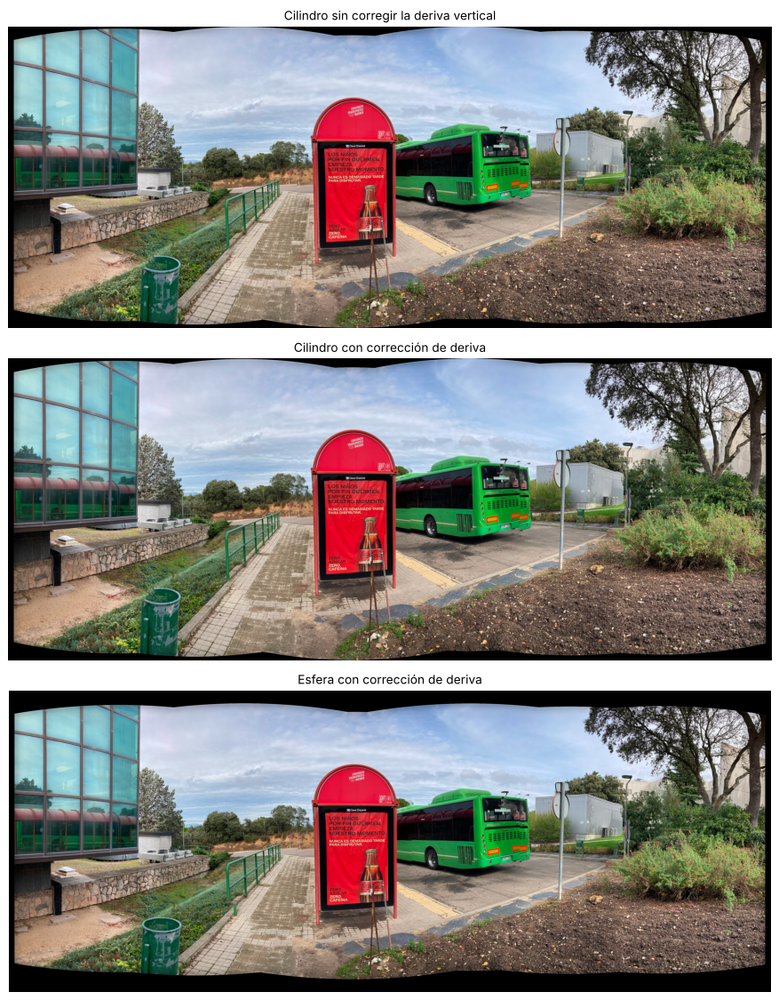

In [15]:
pano_sin, info_sin = P.stitching_wideview(imgs7, MEJOR_METODO, MEJOR_MATCHER, f=F, blending="multibanda",
                                          corregir_deriva=False)
pano_esf, info_esf = P.stitching_wideview(imgs7, MEJOR_METODO, MEJOR_MATCHER, f=F, superficie="esfera",
                                          blending="multibanda")
mostrar([pano_sin, pano_cil, pano_esf],
        ["Cilindro sin corregir la deriva vertical", "Cilindro con corrección de deriva", "Esfera con corrección de deriva"],
        cols=1, alto=4.2, guardar="parte3_proyecciones.png")
del pano_sin, info_sin, pano_esf, info_esf

- La **corrección de deriva** deja el horizonte recto y reduce la altura del lienzo, de modo que se pierde menos imagen al recortar.
- **Cilindro y esfera** dan resultados casi idénticos, porque el campo de visión vertical es pequeño y la componente de latitud apenas influye. La esfera curva un poco más los bordes superior e inferior. Se usa el cilindro.

### 3.3 Fotos desordenadas: recuperación automática del orden

El enunciado pide eliminar la condición de que las fotos lleguen ordenadas. El algoritmo implementado (`P.ordenar_imagenes`) no presupone nada sobre el orden:

1. **Empareja todos los pares** de fotos (21 pares con 7 fotos) y estima la traslación de cada par con RANSAC.
2. Construye un **grafo** cuyos nodos son las fotos y cuyas aristas son los pares con suficientes inliers, con peso igual al número de inliers.
3. Calcula el **árbol de expansión máximo** (algoritmo de Kruskal). Así se conservan solo los solapes más fiables y se descartan los emparejamientos casuales entre fotos que no solapan.
4. Recorre el árbol acumulando las traslaciones para obtener la **posición horizontal** de cada foto, y las ordena de izquierda a derecha.

Funciona con cualquier número de fotos y no necesita saber cuál es la primera. Para probarlo, se desordenan las 7 fotos al azar:

In [16]:
rng = np.random.default_rng(7)
permutacion = rng.permutation(len(imgs7))
desordenadas = [imgs7[i] for i in permutacion]
print("Orden en que se entregan las fotos:", [f"{i}.jpg" for i in permutacion])

pano_desord, info_desord = P.stitching_wideview(desordenadas, MEJOR_METODO, MEJOR_MATCHER, f=F,
                                                ordenadas=False, blending="multibanda")
recuperado = [int(permutacion[i]) for i in info_desord["orden"]]
print("Orden recuperado:                  ", [f"{i}.jpg" for i in recuperado])
print("¿Coincide con el orden real?", recuperado == list(range(7)) or recuperado == list(range(7))[::-1])

Orden en que se entregan las fotos: ['0.jpg', '5.jpg', '6.jpg', '2.jpg', '4.jpg', '1.jpg', '3.jpg']
Orden recuperado:                   ['0.jpg', '1.jpg', '2.jpg', '3.jpg', '4.jpg', '5.jpg', '6.jpg']
¿Coincide con el orden real? True


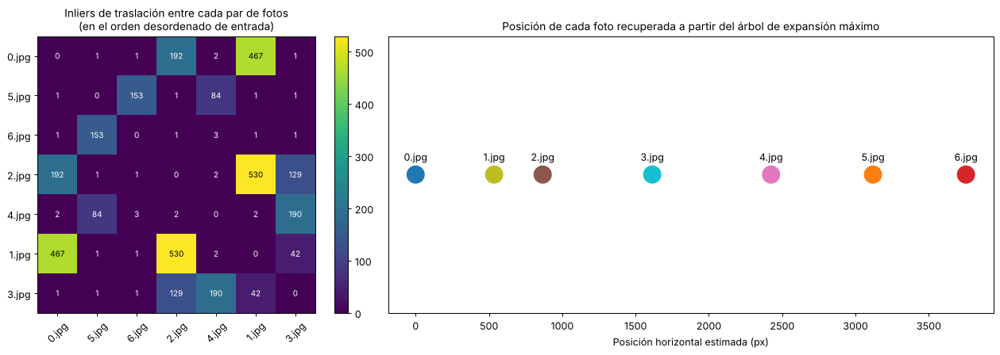

In [17]:
M = info_desord["orden_info"]["matriz_inliers"]
etiquetas = [f"{i}.jpg" for i in permutacion]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.6]})
im = axes[0].imshow(M, cmap="viridis")
axes[0].set_xticks(range(7), etiquetas, rotation=45)
axes[0].set_yticks(range(7), etiquetas)
for i in range(7):
    for j in range(7):
        axes[0].text(j, i, M[i, j], ha="center", va="center", color="w" if M[i, j] < M.max() / 2 else "k", fontsize=8)
axes[0].set_title("Inliers de traslación entre cada par de fotos\n(en el orden desordenado de entrada)")
plt.colorbar(im, ax=axes[0], fraction=0.046)
pos = info_desord["orden_info"]["posiciones_x"]
xs = np.array([pos[i] for i in range(7)])
axes[1].scatter(xs, np.zeros(7), s=300, c=range(7), cmap="tab10")
for i in range(7):
    axes[1].annotate(f"{permutacion[i]}.jpg", (xs[i], 0), textcoords="offset points", xytext=(0, 14), ha="center")
axes[1].set_yticks([])
axes[1].set_xlabel("Posición horizontal estimada (px)")
axes[1].set_title("Posición de cada foto recuperada a partir del árbol de expansión máximo")
plt.tight_layout()
plt.savefig(FIG_DIR / "parte3_orden.png", dpi=110, bbox_inches="tight")
plt.show()
del pano_desord

En la matriz, las fotos contiguas comparten entre 80 y 530 inliers, y las que no solapan apenas 1–3 inliers casuales. Algunas fotos no contiguas también solapan de verdad (por ejemplo, 0 y 2, o 1 y 3), porque la cámara giró entre ellas menos de lo que mide una foto de ancho. Esto no confunde al algoritmo: el árbol de expansión máximo puede usar cualquier solape fiable, ya que lo que determina el orden son las **posiciones acumuladas**, no qué aristas se eligen. El resultado es el orden **0 → 6** sin errores.

### 3.4 Comparación de técnicas de *blending*

Con las fotos ya colocadas en el lienzo, falta decidir qué valor toma cada píxel en las zonas de solape. Se comparan 6 estrategias:

| Estrategia | Idea |
|---|---|
| **Superposición** | Sin mezcla: cada foto pisa a la anterior |
| **Media** | Media aritmética de las fotos que cubren el píxel |
| **Feathering** | Media ponderada por la distancia al borde de cada foto (transición suave) |
| **Máximo peso** | Cada píxel se toma entero de la foto en la que está más lejos del borde |
| **Multibanda** (Burt y Adelson) | Mezcla las pirámides laplacianas: las frecuencias bajas en una franja ancha y las altas en una franja estrecha |
| **GraphCut + multibanda** | Busca la costura de mínimo coste (diferencia de color y gradiente) con cortes de grafo y mezcla con multibanda alrededor de ella |

In [18]:
wi, wm = info_cil["warped"]
blends, tiempos = {}, {}
for nombre, fn in P.BLENDINGS.items():
    t0 = time.perf_counter()
    blends[nombre] = P.recortar_rectangulo_interior(fn(wi, wm), wm)
    tiempos[nombre] = time.perf_counter() - t0
t0 = time.perf_counter()
blends["graphcut + multibanda + exposición"] = P.recortar_rectangulo_interior(
    P.blend_graphcut_multibanda(wi, wm, exposicion=True), wm)
tiempos["graphcut + multibanda + exposición"] = time.perf_counter() - t0
display(pd.Series(tiempos, name="Tiempo (s)").to_frame().style.format(precision=1))

,Tiempo (s)
superposición,0.2
media,0.8
feather,1.1
max_peso,1.1
multibanda,3.7
graphcut+multibanda,25.3
graphcut + multibanda + exposición,39.8


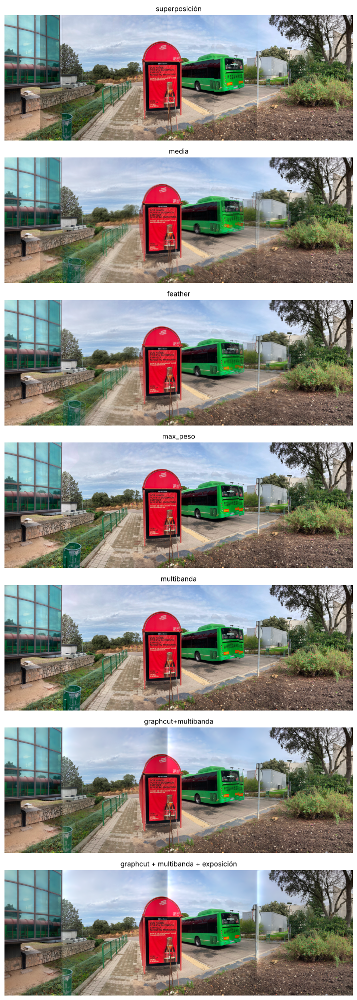

In [19]:
# Vista completa de cada resultado
nombres = list(blends)
mostrar([blends[n] for n in nombres], nombres, cols=1, alto=3.2)

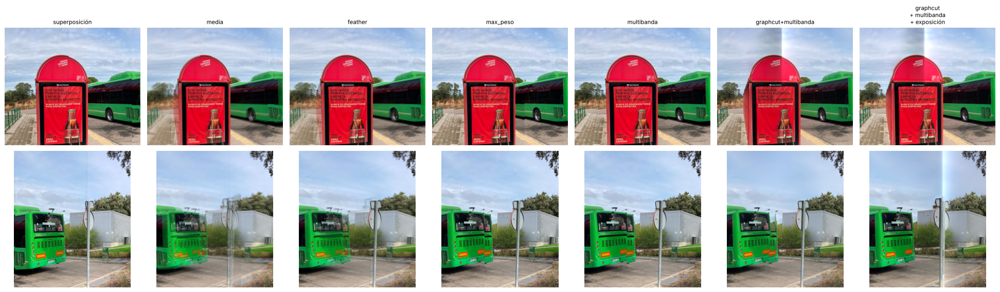

In [20]:
# Detalle de zonas de solape: la marquesina y el autobús, y la señal con el edificio gris
h, w = blends["superposición"].shape[:2]
zonas = {"marquesina y autobús": (int(0.33 * w), int(0.62 * w), int(0.05 * h), int(0.75 * h)),
         "señal y edificio":      (int(0.60 * w), int(0.80 * w), int(0.05 * h), int(0.70 * h))}
fig, axes = plt.subplots(2, len(nombres), figsize=(3.1 * len(nombres), 6.4))
for fila, (zona, (xa, xb, ya, yb)) in enumerate(zonas.items()):
    for col, n in enumerate(nombres):
        axes[fila, col].imshow(blends[n][ya:yb, xa:xb])
        axes[fila, col].axis("off")
        if fila == 0:
            axes[fila, col].set_title(n.replace(" + ", "\n+ "), fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "parte3_blending.png", dpi=110, bbox_inches="tight")
plt.show()

**Artefactos observados en cada estrategia**

Hay dos fuentes de error: pequeñas **diferencias de brillo** entre fotos (exposición automática y viñeteado del móvil) y **objetos en movimiento**. El autobús se movió entre las fotos 4 y 5, así que no está en el mismo sitio en las dos.

| Estrategia | Artefactos | Comentario |
|---|---|---|
| Superposición | Costuras rectas visibles y saltos de brillo | La más rápida, pero cada borde de foto se nota |
| Media | **Fantasmas** muy marcados (autobús y señal duplicados y semitransparentes) | Mezcla por igual píxeles que no coinciden |
| Feathering | Fantasmas más suaves, pero visibles, y desenfoque en los solapes | La transición de brillo sí es suave |
| Máximo peso | Sin desenfoque, pero la costura **corta el autobús**, que aparece con la parte trasera duplicada | Cada píxel viene de una sola foto |
| Multibanda | Ningún salto de brillo ni desenfoque; **el autobús sigue cortado** | La mezcla por frecuencias elimina las costuras de brillo, pero no puede arreglar un objeto que se ha movido |
| GraphCut + multibanda | **El autobús queda entero**, pero aparecen **franjas de brillo en el cielo** | La costura óptima rodea los objetos con mucho detalle y atraviesa las zonas lisas, donde cualquier diferencia de brillo se nota. Es el más lento |
| … con compensación de exposición | Franjas en el cielo aún más marcadas | Una ganancia global por foto no corrige el viñeteado, que oscurece los bordes justo donde están los solapes |

**Elección final: multibanda.** Es la que da el mejor resultado global en un tiempo razonable: costuras invisibles y nada de fantasmas en las zonas estáticas. Su único defecto es el autobús, y lo comparten todas las técnicas salvo GraphCut. GraphCut es la opción correcta para objetos en movimiento, pero en esta escena las franjas del cielo son más llamativas. Combinar lo mejor de ambas exigiría una compensación de exposición local, por bloques y con corrección de viñeteado, antes del corte de grafo.

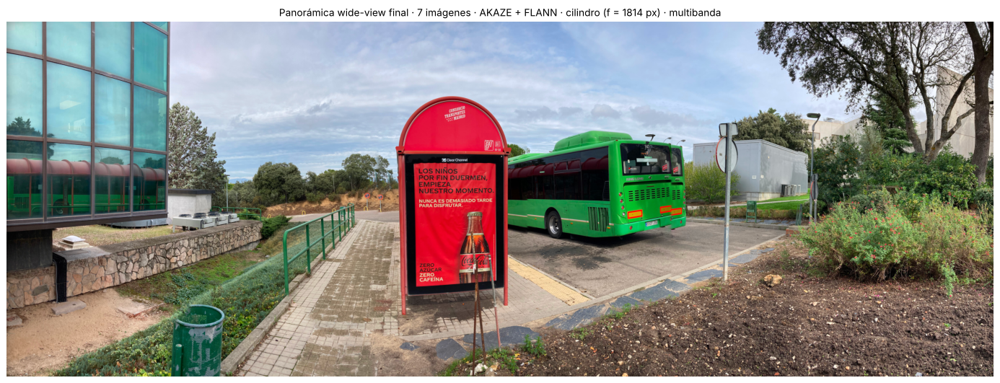

Tamaño de la panorámica final: 5165 x 1858 px


In [21]:
final = blends["multibanda"]
mostrar(final, [f"Panorámica wide-view final · 7 imágenes · {elegido['Método']} + {elegido['Matcher']} · cilindro (f = {F:.0f} px) · multibanda"], alto=6)
guardar_jpg(final, "panorama_final.jpg", ancho_max=3000)
print("Tamaño de la panorámica final:", final.shape[1], "x", final.shape[0], "px")

---
# Conclusiones

- **Detectores y descriptores.** Los detectores con **estimación de escala** son imprescindibles cuando el objeto cambia de tamaño entre imágenes: las esquinas sin escala (GFTT) fallan, mientras que ORB y BRISK funcionan gracias a sus pirámides. Para el panorama, **AKAZE + FLANN** dio el mejor equilibrio entre robustez y tiempo. KAZE es el más robusto pero también el más lento, y ORB el más rápido.
- **Geometría.** Las homografías encadenadas bastan para unas pocas fotos, pero el orden del producto es crítico, y se corrigió un error de la entrega original. Para panorámicas amplias, la **proyección cilíndrica con traslaciones** es mucho más estable, siempre que la **focal** sea correcta. Estimarla a partir de los propios datos aumentó los inliers del par más débil frente a la heurística original.
- **Orden desconocido.** Un grafo de solapes con su **árbol de expansión máximo** recupera el orden de las fotos sin ninguna información previa.
- **Blending.** La **mezcla multibanda** elimina las costuras de brillo y los fantasmas de las zonas estáticas, mientras que la media y el *feathering* producen fantasmas. Con **objetos en movimiento** (el autobús), solo la costura óptima de **GraphCut** evita cortarlos, a cambio de saltos de brillo en zonas lisas. La compensación de exposición global no ayuda cuando hay viñeteado.